In [1]:
import xarray as xr
from datetime import datetime, date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds = xr.load_dataset("target_variables/grib_files/t2m_40_45.grib", engine="cfgrib")
var_daily1 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_40_45.grib.5b7b6.idx' incompatible with GRIB file


In [3]:
ds = xr.load_dataset("target_variables/grib_files/t2m_46_51.grib", engine="cfgrib")
var_daily2 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_46_51.grib.5b7b6.idx' incompatible with GRIB file


In [4]:
ds = xr.load_dataset("target_variables/grib_files/t2m_52_57.grib", engine="cfgrib")
var_daily3 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_52_57.grib.5b7b6.idx' incompatible with GRIB file


In [5]:
ds = xr.load_dataset("target_variables/grib_files/t2m_58_63.grib", engine="cfgrib")
var_daily4 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_58_63.grib.5b7b6.idx' incompatible with GRIB file


In [6]:
ds = xr.load_dataset("target_variables/grib_files/t2m_64_69.grib", engine="cfgrib")
var_daily5 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_64_69.grib.5b7b6.idx' incompatible with GRIB file


In [7]:
ds = xr.load_dataset("target_variables/grib_files/t2m_70_75.grib", engine="cfgrib")
var_daily6 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_70_75.grib.5b7b6.idx' incompatible with GRIB file


In [8]:
ds = xr.load_dataset("target_variables/grib_files/t2m_76_81.grib", engine="cfgrib")
var_daily7 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_76_81.grib.5b7b6.idx' incompatible with GRIB file


In [9]:
ds = xr.load_dataset("target_variables/grib_files/t2m_82_87.grib", engine="cfgrib")
var_daily8 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_82_87.grib.5b7b6.idx' incompatible with GRIB file


In [10]:
ds = xr.load_dataset("target_variables/grib_files/t2m_88_93.grib", engine="cfgrib")
var_daily9 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_88_93.grib.5b7b6.idx' incompatible with GRIB file


In [11]:
ds = xr.load_dataset("target_variables/grib_files/t2m_94_99.grib", engine="cfgrib")
var_daily10 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_94_99.grib.5b7b6.idx' incompatible with GRIB file


In [12]:
ds = xr.load_dataset("target_variables/grib_files/t2m_00_05.grib", engine="cfgrib")
var_daily11 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_00_05.grib.5b7b6.idx' incompatible with GRIB file


In [13]:
ds = xr.load_dataset("target_variables/grib_files/t2m_06_10.grib", engine="cfgrib")
var_daily12 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_06_10.grib.5b7b6.idx' incompatible with GRIB file


In [14]:
ds = xr.load_dataset("target_variables/grib_files/t2m_11_15.grib", engine="cfgrib")
var_daily13 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_11_15.grib.5b7b6.idx' incompatible with GRIB file


In [15]:
ds = xr.load_dataset("target_variables/grib_files/t2m_16_20.grib", engine="cfgrib")
var_daily14 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_16_20.grib.5b7b6.idx' incompatible with GRIB file


In [16]:
ds = xr.load_dataset("target_variables/grib_files/t2m_21_25.grib", engine="cfgrib")
var_daily15 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_21_25.grib.5b7b6.idx' incompatible with GRIB file


In [17]:
var_daily = xr.concat([var_daily1, var_daily2, var_daily3, var_daily4, var_daily5, var_daily6, var_daily7, var_daily8, var_daily9, var_daily10, 
                       var_daily11, var_daily12, var_daily13, var_daily14, var_daily15], dim='date')

In [18]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [19]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [20]:
var_daily = var_daily.reset_coords(['number', 'step', 'surface'], drop=True)
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=(month==12)|(month==1)|((month==2) & (day<29)))

In [21]:
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})

### Spatial weights

In [22]:
ds_oro = xr.load_dataset("target_variables/grib_files/orography_original_res.grib", engine="cfgrib")

Ignoring index file 'target_variables/grib_files/orography_original_res.grib.5b7b6.idx' incompatible with GRIB file


In [23]:
g = 9.80665

In [24]:
ds_oro = ds_oro.reset_coords(['number', 'time', 'step', 'surface', 'valid_time'], drop=True)

In [25]:
lat = ds_oro.latitude
land_frac = ds_oro.lsm + ds_oro.cl
mount_filt = xr.where(ds_oro.z/g < 1000, 1, 0)

In [26]:
weights = np.cos(np.deg2rad(lat))*land_frac*mount_filt
weights.name = "weights"

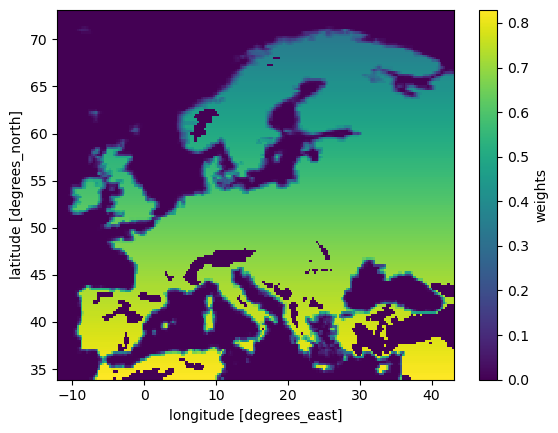

In [27]:
weights.plot()

### Time series of region means

**Northern Europe**: 4°E-42°E, 59°N-72°N  
**Western-Central Europe**: 11°W-19°E, 47°N-59°N  
**Eastern Europe**: 19°E-42°E, 47°N-59°N  
**Southwestern Europe**: 10°W-10°E, 36°N-47°N  
**Southeastern Europe**: 10°E-30°E, 35°N-47°N

In [28]:
# Choose extent of the region:

lon_min = -11
lon_max = 19
lat_max = 59
lat_min = 47

var_daily_regmean = var_daily.sel(longitude=slice(lon_min,lon_max), latitude=slice(lat_max,lat_min)).weighted(weights).mean(dim=['longitude', 'latitude'])

In [29]:
var_seasonmean_regmean = var_daily_regmean.coarsen(time=90).construct(time=("year", "date")).mean(dim='date')

In [30]:
df_gmst = pd.read_csv('era5-0p5deg_world_t2_surface_anom_1951-2000_table.csv', delimiter=',', skiprows=8, usecols=(0,14))
df_gmst = df_gmst.drop(index=0)
fit_par = np.polyfit(df_gmst[:70]['Year'], df_gmst[:70]['DJF'], 2)
df_gmst['quadr_fit'] = np.polyval(fit_par, df_gmst['Year'])

<Axes: >

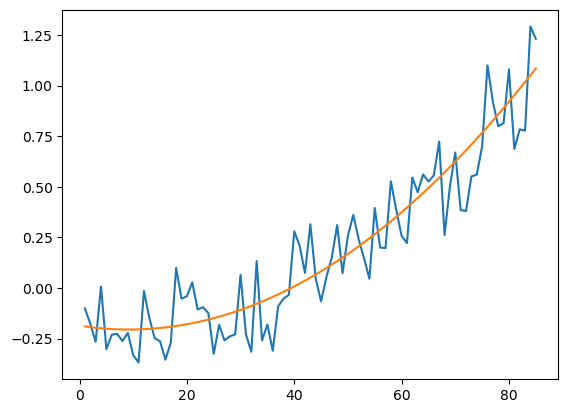

In [31]:
df_gmst['DJF'][:-1].plot()
df_gmst['quadr_fit'][:-1].plot()

In [32]:
fit_par = np.polyfit(df_gmst[10:70]['quadr_fit'], var_seasonmean_regmean[:60], 1)
var_seasonmean_regmean_gws_quadr = np.polyval(fit_par, df_gmst[10:-1]['quadr_fit'])

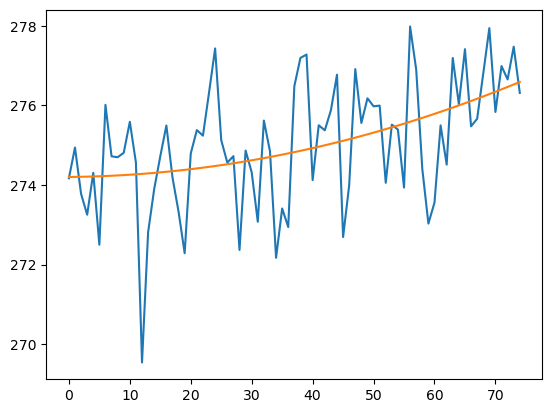

In [33]:
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean)
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean_gws_quadr)

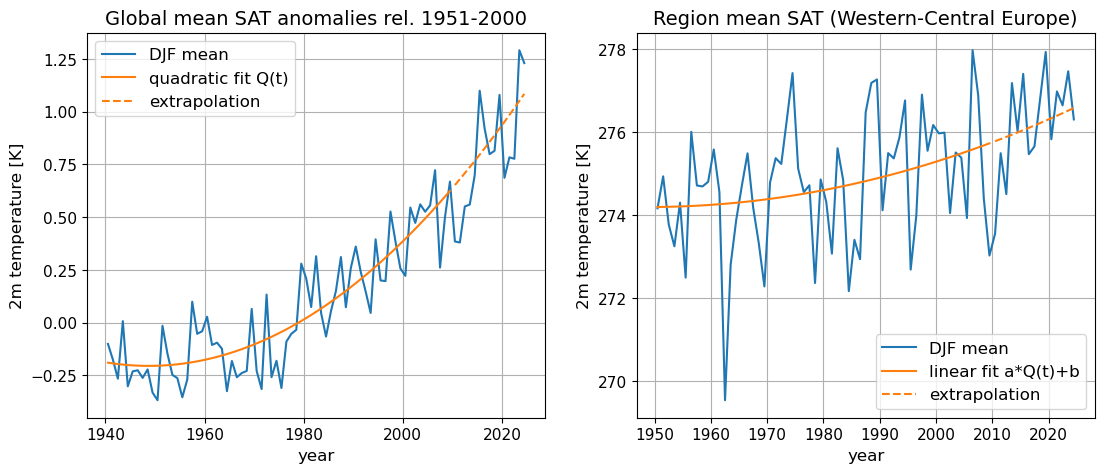

In [38]:
fig, ax = plt.subplots(1,2,figsize=(13,5))

ax[0].plot(np.linspace(1940.5,2024.5,85),df_gmst['DJF'][:-1], label='DJF mean')
ax[0].plot(np.linspace(1940.5,2009.5,70),df_gmst['quadr_fit'][:70], label='quadratic fit Q(t)')
ax[0].plot(np.linspace(2010.5,2024.5,15),df_gmst['quadr_fit'][70:-1], color='tab:orange', linestyle='--', label='extrapolation')
ax[0].set_xlabel('year',fontsize=12)
ax[0].set_ylabel('2m temperature [K]',fontsize=12)
ax[0].set_title('Global mean SAT anomalies rel. 1951-2000',fontsize=14)
ax[0].legend(fontsize=12)
ax[0].grid()
ax[0].tick_params(labelsize=11)


ax[1].plot(np.linspace(1950.5,2024.5,75),var_seasonmean_regmean, label='DJF mean')
ax[1].plot(np.linspace(1950.5,2009.5,60),var_seasonmean_regmean_gws_quadr[:60], label='linear fit a*Q(t)+b')
ax[1].plot(np.linspace(2010.5,2024.5,15),var_seasonmean_regmean_gws_quadr[60:], color='tab:orange', linestyle='--', label='extrapolation')
ax[1].set_xlabel('year',fontsize=12)
ax[1].set_ylabel('2m temperature [K]',fontsize=12)
ax[1].set_title('Region mean SAT (Western-Central Europe)',fontsize=14)
ax[1].legend(fontsize=12)
ax[1].grid()
ax[1].tick_params(labelsize=11)

plt.savefig('detrending_temp.pdf', bbox_inches='tight')

In [34]:
var_daily_regmean_detr_quadr = var_daily_regmean.coarsen(time=90).construct(time=("year", "date")) - var_seasonmean_regmean_gws_quadr[:, np.newaxis]
var_daily_regmean_detr_quadr = var_daily_regmean_detr_quadr.stack(day=("year", "date")).swap_dims({"day": "time"}).reset_coords(('day','year','date'), drop=True)

In [35]:
var_7dMean_regmean_detr_quadr = var_daily_regmean_detr_quadr.rolling(time=7, min_periods=7, center=True).mean()

In [36]:
month = var_7dMean_regmean_detr_quadr.time.dt.month
day = var_7dMean_regmean_detr_quadr.time.dt.day
var_7dMean_regmean_detr_quadr = var_7dMean_regmean_detr_quadr.sel(time=~( ((month==12)&(day<4)) | ((month==2)&(day>25)) ))

In [115]:
var_7dMean_regmean_detr_quadr_train = var_7dMean_regmean_detr_quadr.sel(time=slice("1950-07", "2010-06"))

In [116]:
var_7dMean_regmean_detr_quadr_monthlyanom = var_7dMean_regmean_detr_quadr.groupby('time.month') - var_7dMean_regmean_detr_quadr_train.groupby('time.month').mean()
var_7dMean_regmean_detr_quadr_monthlyanom.plot()

In [126]:
df_var = var_7dMean_regmean_detr_quadr_monthlyanom.to_dataframe()
df_var = df_var.drop(['month_day', 'month'], axis=1)
df_var.to_csv('target_temp_NE_quadr_moanom.csv')